# DermaGuard — Full 6-Agent Evaluation Pipeline
**Jaypee Agentic AI International Summit 2026 | Track 2: Healthcare**

This notebook runs the complete DermaGuard pipeline on ~200 hidden evaluation images:
1. **Agent 1** – Image Quality Check (blur, lighting, glare, occlusion)
2. **Agent 2** – Diagnosis: 4-model ensemble (EfficientNet-B0/B3, ResNet-50, ViT-Small) + TTA
3. **Agent 3** – Lesion Analysis: ABCD morphometrics via Otsu segmentation
4. **Agent 4** – Patient Risk: metadata-driven risk stratification
5. **Agent 5** – Safety Review: malignancy override policy
6. **Agent 6** – Final Decision: REFER / MONITOR / ROUTINE with confidence

> **No Gemini LLM is used** – fully deterministic, GPU-ready, runs on ~200 images efficiently.

## Step 1 · Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')
print("✅ Drive mounted")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Drive mounted


## Step 2 · Install Dependencies

In [2]:
import subprocess, sys

pkgs = {
    "timm":          "timm",
    "scikit-learn":  "sklearn",
    "matplotlib":    "matplotlib",
    "seaborn":       "seaborn",
    "tqdm":          "tqdm",
    "pandas":        "pandas",
    "pillow":        "PIL",
    "numpy":         "numpy",
    "opencv-python": "cv2",
}

to_install = []
for pkg, imp in pkgs.items():
    try:
        __import__(imp)
    except ImportError:
        to_install.append(pkg)

if to_install:
    print(f"Installing: {to_install}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + to_install)
else:
    print("✅ All packages already installed")

✅ All packages already installed


## Step 3 · Imports & Reproducibility

In [3]:
import os, random, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import timm
import cv2

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

✅ Using device: cuda
   GPU: Tesla T4
   VRAM: 15.6 GB


## Step 4 · Configuration

> ✏️ **Edit paths here if needed**

In [4]:
# ── Locate evaluation zip file in Google Drive ──────────────────────────────
# Auto-detects health-training.zip (current test) or health-eval.zip (eval test)
ZIP_CANDIDATES = [
    Path('/content/drive/MyDrive/health-eval.zip'),
    Path('/content/drive/MyDrive/Health.zip'),
]
ZIP_PATH = None
for z in ZIP_CANDIDATES:
    if z.exists():
        ZIP_PATH = z
        break
if ZIP_PATH is None:
    ZIP_PATH = Path('/content/drive/MyDrive/health-eval.zip')

EXTRACT_DIR     = Path('/content/health-eval')                          # ← extraction root
EVAL_IMAGE_DIR  = EXTRACT_DIR / 'Health' / 'eval' / 'images'                     # ← default image dir (will auto-discover)

# ── Model checkpoints in Drive from training ────────────────────────────────
CHECKPOINT_DIR  = Path('/content/drive/MyDrive/dermaguard_checkpoints')

# ── Local Output directory ──────────────────────────────────────────────────
OUTPUT_DIR      = Path('/content/drive/MyDrive/dermaguard_eval_output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Model constants (must match training) ────────────────────────────────────
IMG_SIZE        = 224
TEMPERATURE     = 1.2            # Conservative calibration (T>1 softens probabilities)
NUM_CLASSES     = 7
LABEL_MAP       = {"nv":0, "mel":1, "bkl":2, "bcc":3, "akiec":4, "vasc":5, "df":6}
IDX_TO_CLASS    = {v: k for k, v in LABEL_MAP.items()}
CLASS_NAMES     = [IDX_TO_CLASS[i] for i in range(7)]
IMAGENET_MEAN   = [0.485, 0.456, 0.406]
IMAGENET_STD    = [0.229, 0.224, 0.225]

# ── Malignant classes (always REFER) ─────────────────────────────────────────
MALIGNANT_CLASSES = {"mel", "bcc", "akiec"}

print("✅ Configuration loaded")
print(f"   Candidate ZIP  : {ZIP_PATH} (exists: {ZIP_PATH.exists()})")
print(f"   EXTRACT_DIR    : {EXTRACT_DIR}")
print(f"   CHECKPOINT_DIR : {CHECKPOINT_DIR} (exists: {CHECKPOINT_DIR.exists()})")
print(f"   OUTPUT_DIR     : {OUTPUT_DIR}")
print(f"   CLASS_NAMES    : {CLASS_NAMES}")


✅ Configuration loaded
   Candidate ZIP  : /content/drive/MyDrive/health-eval.zip (exists: True)
   EXTRACT_DIR    : /content/health-eval
   CHECKPOINT_DIR : /content/drive/MyDrive/dermaguard_checkpoints (exists: True)
   OUTPUT_DIR     : /content/drive/MyDrive/dermaguard_eval_output
   CLASS_NAMES    : ['nv', 'mel', 'bkl', 'bcc', 'akiec', 'vasc', 'df']


## Step 5 · Extract Evaluation Dataset

In [5]:
# ── Extract zip if not already done ─────────────────────────────────────────
SUPPORTED_EXTS = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}

# Check if images already exist in extract directory
existing_imgs = [p for p in EXTRACT_DIR.rglob("*") if p.suffix in SUPPORTED_EXTS] if EXTRACT_DIR.exists() else []

if len(existing_imgs) > 0:
    print(f"✅ Already extracted — found {len(existing_imgs)} images under {EXTRACT_DIR}")
else:
    if not ZIP_PATH.exists():
        # Check if user has uploaded zip with another name in Drive
        found_zips = list(Path('/content/drive/MyDrive').glob("*.zip")) if Path('/content/drive/MyDrive').exists() else []
        zip_msg = f"Available zips in MyDrive: {[z.name for z in found_zips]}" if found_zips else "No .zip files found in MyDrive."
        raise FileNotFoundError(
            f"ZIP not found: {ZIP_PATH}\n{zip_msg}\n"
            "Please upload your evaluation zip to Google Drive and update ZIP_PATH."
        )
    print(f"📦 Extracting {ZIP_PATH} → {EXTRACT_DIR} ...")
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(EXTRACT_DIR)
    print("✅ Extraction complete")

# ── Auto-discover image directory ───────────────────────────────────────────
candidate_dirs = [
    EXTRACT_DIR / 'Health' / 'eval',
    EXTRACT_DIR / 'Health' / 'eval' / 'images',
    EXTRACT_DIR / 'Health' / 'training',
    EXTRACT_DIR / 'Health' / 'training' / 'images',
    EXTRACT_DIR / 'eval',
    EXTRACT_DIR / 'eval' / 'images',
    EXTRACT_DIR / 'images',
    EXTRACT_DIR,
]

EVAL_IMAGE_DIR = None
for cdir in candidate_dirs:
    if cdir.exists():
        found = [p for p in cdir.iterdir() if p.suffix in SUPPORTED_EXTS]
        if found:
            EVAL_IMAGE_DIR = cdir
            break

if EVAL_IMAGE_DIR is None:
    all_imgs = [p for p in EXTRACT_DIR.rglob("*") if p.suffix in SUPPORTED_EXTS]
    if all_imgs:
        EVAL_IMAGE_DIR = all_imgs[0].parent
    else:
        raise FileNotFoundError(f"No image files ({SUPPORTED_EXTS}) found anywhere in {EXTRACT_DIR}")

image_paths = sorted([p for p in EVAL_IMAGE_DIR.iterdir() if p.suffix in SUPPORTED_EXTS])
print(f"\n📊 Discovered image directory: {EVAL_IMAGE_DIR}")
print(f"   Evaluation set: {len(image_paths)} images")
print(f"   Sample IDs: {[p.stem for p in image_paths[:5]]}")

# ── Detect whether true labels are available (via metadata.csv with 'dx' col) ─
LABELS_AVAILABLE = False
true_label_map   = {}   # image_id → true class string e.g. "mel"

for meta_candidate in [
    EVAL_IMAGE_DIR / "metadata.csv",
    EVAL_IMAGE_DIR.parent / "metadata.csv",
    EXTRACT_DIR / "metadata.csv",
    EXTRACT_DIR / "Health" / "eval" / "metadata.csv",
    EXTRACT_DIR / "Health" / "training" / "metadata.csv",
]:
    if meta_candidate.exists():
        _meta = pd.read_csv(meta_candidate)
        id_col = next((c for c in ["image_id", "image", "isic_id", "id"] if c in _meta.columns), None)
        if "dx" in _meta.columns and id_col is not None:
            for _, r in _meta.iterrows():
                dx_val = str(r["dx"]).strip()
                raw_id = str(r[id_col]).strip()
                clean_id = Path(raw_id).stem
                true_label_map[clean_id] = dx_val
                true_label_map[raw_id]   = dx_val
            LABELS_AVAILABLE = True
            print(f"\n🏷️  True labels found in: {meta_candidate}")
            print(f"   {len(set(true_label_map.keys()))} labelled entries mapped")
            print(f"   Label distribution:")
            print(_meta["dx"].value_counts().to_string())
            break

if not LABELS_AVAILABLE:
    print("\nℹ️  No ground-truth labels found — running in PREDICTION-ONLY mode")
    print("   (Accuracy metrics will be skipped, expected for unlabelled test sets)")


✅ Already extracted — found 1942 images under /content/health-eval

📊 Discovered image directory: /content/health-eval/Health/eval/images
   Evaluation set: 1942 images
   Sample IDs: ['ISIC_0024317', 'ISIC_0024330', 'ISIC_0024332', 'ISIC_0024340', 'ISIC_0024341']

🏷️  True labels found in: /content/health-eval/Health/eval/metadata.csv
   1942 labelled entries mapped
   Label distribution:
dx
nv       1302
mel       214
bkl       212
bcc       101
akiec      63
vasc       27
df         23


## Step 6 · Load 4 Model Checkpoints

In [6]:
# ── Candidate Model Specs & Checkpoint Discovery ─────────────────────────────
# Supports the 4 core models + optional DenseNet / ConvNeXt if trained
CANDIDATE_SPECS = [
    ("efficientnet_b0",       ["best_efficientnet_b0.pth", "efficientnet_b0.pth"]),
    ("efficientnet_b3",       ["best_efficientnet_b3.pth", "efficientnet_b3.pth"]),
    ("resnet50",              ["best_resnet50.pth", "resnet50.pth"]),
    ("vit_small_patch16_224", ["best_vit_small.pth", "vit_small.pth", "best_vit.pth"]),
    ("densenet121",           ["best_densenet121.pth", "densenet121.pth", "best_densenet.pth"]),
    ("convnext_tiny",         ["best_convnext_tiny.pth", "convnext_tiny.pth", "best_convnext.pth"]),
]

LOCAL_CKPT_DIR = Path('/content/checkpoints')
LOCAL_CKPT_DIR.mkdir(exist_ok=True)

loaded_models = []  # list of (name, model)

for timm_name, candidate_files in CANDIDATE_SPECS:
    ckpt_local = None
    # 1. Check if already local
    for cf in candidate_files:
        if (LOCAL_CKPT_DIR / cf).exists():
            ckpt_local = LOCAL_CKPT_DIR / cf
            break
    # 2. Check in CHECKPOINT_DIR in Drive
    if ckpt_local is None:
        for cf in candidate_files:
            src = CHECKPOINT_DIR / cf
            if src.exists():
                dst = LOCAL_CKPT_DIR / cf
                import shutil
                shutil.copy2(src, dst)
                print(f"   📋 Copied {cf} from Drive → /content/checkpoints")
                ckpt_local = dst
                break

    if ckpt_local is None:
        continue

    print(f"   Loading {timm_name} from {ckpt_local.name}...", end=" ")
    try:
        m = timm.create_model(timm_name, pretrained=False, num_classes=NUM_CLASSES)
        state = torch.load(ckpt_local, map_location=DEVICE)
        # Handle wrapped state dicts
        if isinstance(state, dict) and "state_dict" in state:
            state = state["state_dict"]
        m.load_state_dict(state)
        m.to(DEVICE).eval()
        loaded_models.append((timm_name, m))
        print("✅")
    except Exception as e:
        print(f"❌ Error: {e}")

print(f"\n🚀 Ensemble ready: {len(loaded_models)} model(s) loaded")
for name, _ in loaded_models:
    print(f"   • {name}")

if len(loaded_models) == 0:
    raise RuntimeError(
        f"No models loaded! Please verify checkpoints exist in {CHECKPOINT_DIR}."
    )


   Loading efficientnet_b0 from best_efficientnet_b0.pth... ✅
   Loading efficientnet_b3 from best_efficientnet_b3.pth... ✅
   Loading resnet50 from best_resnet50.pth... ✅
   Loading vit_small_patch16_224 from best_vit_small.pth... ✅

🚀 Ensemble ready: 4 model(s) loaded
   • efficientnet_b0
   • efficientnet_b3
   • resnet50
   • vit_small_patch16_224


## Step 7 · Preprocessing (Shades of Gray + TTA Transforms)

In [7]:
# ── Shades-of-Gray colour normalisation (must match training) ──────────────
def shades_of_gray(img_np, power=6):
    """Illumination-invariant colour normalisation (Finlayson et al.)"""
    img  = img_np.astype(np.float32)
    norm = np.power(np.mean(np.power(img, power), axis=(0, 1)), 1.0 / power)
    norm = norm / (norm.mean() + 1e-8)
    return np.clip(img / (norm + 1e-8), 0, 255).astype(np.uint8)

RESAMPLE = Image.Resampling.BILINEAR

def preprocess(img_path):
    """Load → Shades-of-Gray → resize to 224×224 PIL Image."""
    img_np  = np.array(Image.open(img_path).convert("RGB"))
    img_sog = shades_of_gray(img_np)
    return Image.fromarray(img_sog).resize((IMG_SIZE, IMG_SIZE), RESAMPLE)

# ── 4-fold TTA (same as training notebook) ───────────────────────────────────
tta_transforms = [
    T.Compose([T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.RandomHorizontalFlip(p=1.0), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.RandomVerticalFlip(p=1.0),   T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    T.Compose([T.RandomHorizontalFlip(p=1.0), T.RandomVerticalFlip(p=1.0),
               T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
]

print(f"✅ {len(tta_transforms)}-fold TTA defined")
print(f"   Shades-of-Gray normalisation: ON (power=6)")
print(f"   Temperature scaling: T = {TEMPERATURE}")

✅ 4-fold TTA defined
   Shades-of-Gray normalisation: ON (power=6)
   Temperature scaling: T = 1.2


## Agent 1 — Image Quality Checker

In [8]:
class ImageQualityAgent:
    """
    Agent 1: Checks dermoscopic image quality.
    Returns quality_pass (bool) + per-metric scores.
    """
    # Thresholds tuned for dermoscopic images
    BLUR_THRESH      = 60.0
    DARK_THRESH      = 35.0
    BRIGHT_THRESH    = 230.0
    GLARE_THRESH     = 0.025
    OCCLUDE_THRESH   = 0.30

    def __call__(self, img_path):
        img = cv2.imread(str(img_path))
        if img is None:
            return {"quality_pass": False, "reason": "cannot_open",
                    "blur": 0, "brightness": 0, "glare_ratio": 1, "occlude_ratio": 1}

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # ── Blur (Laplacian variance) ────────────────────────────────────────
        blur_score = float(cv2.Laplacian(gray, cv2.CV_64F).var())

        # ── Brightness (mean of luminance channel) ───────────────────────────
        lab        = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
        brightness = float(lab[:, :, 0].mean())

        # ── Glare (% pixels saturated) ───────────────────────────────────────
        hsv         = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        glare_ratio = float((hsv[:, :, 2] > 250).mean())

        # ── Occlusion / dark corners ─────────────────────────────────────────
        occlude_ratio = float((gray < 20).mean())

        failures = []
        if blur_score     < self.BLUR_THRESH:      failures.append(f"blur={blur_score:.1f}")
        if brightness     < self.DARK_THRESH:       failures.append(f"dark={brightness:.1f}")
        if brightness     > self.BRIGHT_THRESH:     failures.append(f"overexposed={brightness:.1f}")
        if glare_ratio    > self.GLARE_THRESH:      failures.append(f"glare={glare_ratio:.3f}")
        if occlude_ratio  > self.OCCLUDE_THRESH:    failures.append(f"occlusion={occlude_ratio:.2f}")

        return {
            "quality_pass":  len(failures) == 0,
            "reason":        "; ".join(failures) if failures else "pass",
            "blur":          round(blur_score, 2),
            "brightness":    round(brightness, 2),
            "glare_ratio":   round(glare_ratio, 4),
            "occlude_ratio": round(occlude_ratio, 4),
        }

agent1 = ImageQualityAgent()
print("✅ Agent 1 (Image Quality) ready")

✅ Agent 1 (Image Quality) ready


## Agent 2 — Diagnosis Agent (4-Model Ensemble + TTA)

In [9]:
class DiagnosisAgent:
    """
    Agent 2: 4-model ensemble with TTA + temperature scaling.
    Inputs  : image_path (Path or str)
    Outputs : predicted_class, confidence, class_probs, melanoma_flag, melanoma_prob, models_used
    """
    def __init__(self, models, temperature=TEMPERATURE, device=DEVICE):
        self.models      = models      # list of (name, model)
        self.temperature = temperature
        self.device      = device

    def _probs_single(self, model, img_pil):
        """4-fold TTA, temperature-scaled softmax."""
        avg = np.zeros(NUM_CLASSES, dtype=np.float32)
        with torch.no_grad():
            for tfm in tta_transforms:
                t      = tfm(img_pil).unsqueeze(0).to(self.device)
                logits = model(t) / self.temperature
                avg   += F.softmax(logits, dim=1).cpu().numpy()[0]
        return avg / len(tta_transforms)

    def predict(self, img_path):
        img_pil   = preprocess(img_path)
        all_probs = np.stack([self._probs_single(m, img_pil) for _, m in self.models])
        probs     = all_probs.mean(axis=0)

        top_idx   = int(probs.argmax())
        top_class = IDX_TO_CLASS[top_idx]
        mel_prob  = float(probs[LABEL_MAP["mel"]])
        malignant_prob = float(sum(probs[LABEL_MAP[c]] for c in MALIGNANT_CLASSES))

        return {
            "predicted_class":  top_class,
            "confidence":       round(float(probs[top_idx]), 4),
            "class_probs":      {IDX_TO_CLASS[i]: round(float(p), 4) for i, p in enumerate(probs)},
            "melanoma_flag":    (top_class == "mel") or (mel_prob > 0.30),
            "melanoma_prob":    round(mel_prob, 4),
            "malignant_prob":   round(malignant_prob, 4),
            "is_malignant":     top_class in MALIGNANT_CLASSES,
            "models_used":      [n for n, _ in self.models],
        }

agent2 = DiagnosisAgent(loaded_models, temperature=TEMPERATURE, device=DEVICE)
print("✅ Agent 2 (Diagnosis) ready")

✅ Agent 2 (Diagnosis) ready


## Agent 3 — Lesion Analysis Agent (U-Net Segmentation + ABCD Morphometrics)

Segments the lesion with a **PyTorch U-Net** (ISIC-trained checkpoint if available) or falls back to an **enhanced Otsu morphological** segmentation.  
ABCD features are then computed on the binary mask:

| Feature | Description |
|---|---|
| **A** – Asymmetry | Flip XOR overlap ratio (0 = symmetric) |
| **B** – Border | Circularity index (perimeter²/4πA; 1 = circle) |
| **C** – Colour | Mean std of RGB channels within lesion mask |
| **D** – Diameter | Equivalent circle diameter in pixels |

> **U-Net checkpoint**: Place `unet_isic.pth` in `CHECKPOINT_DIR` on Drive to activate deep segmentation.  
> If not found, the enhanced dual-channel Otsu fallback is used automatically.

In [10]:
# ═══════════════════════════════════════════════════════════════════════════
#  U-Net Architecture  (mirrors lesion_analysis_agent/unet.py)
# ═══════════════════════════════════════════════════════════════════════════

class DoubleConv(nn.Module):
    """(Conv2d -> BatchNorm -> ReLU) x 2"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.block(x)


class UNet(nn.Module):
    """
    Standard U-Net for binary skin-lesion segmentation.
    Input:  (B, 3, H, W)  - RGB image, ImageNet-normalised
    Output: (B, 1, H, W)  - raw logits  (sigmoid -> probability mask)
    Architecture: encoder depth 32->64->128->256->512, symmetric decoder.
    """
    def __init__(self, n_channels=3, n_classes=1):
        super().__init__()
        self.inc   = DoubleConv(n_channels, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32,  64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64,  128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        self.down4 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(256, 512))
        # Decoder with skip connections
        self.up1 = nn.ConvTranspose2d(512, 256, 2, stride=2); self.cu1 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2); self.cu2 = DoubleConv(256, 128)
        self.up3 = nn.ConvTranspose2d(128,  64, 2, stride=2); self.cu3 = DoubleConv(128, 64)
        self.up4 = nn.ConvTranspose2d( 64,  32, 2, stride=2); self.cu4 = DoubleConv(64,  32)
        self.outc = nn.Conv2d(32, n_classes, 1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1); x3 = self.down2(x2)
        x4 = self.down3(x3); x5 = self.down4(x4)
        x  = self.cu1(torch.cat([x4, self.up1(x5)], 1))
        x  = self.cu2(torch.cat([x3, self.up2(x)],  1))
        x  = self.cu3(torch.cat([x2, self.up3(x)],  1))
        x  = self.cu4(torch.cat([x1, self.up4(x)],  1))
        return self.outc(x)


# ═══════════════════════════════════════════════════════════════════════════
#  UNetSegmenter — loads checkpoint or falls back to enhanced Otsu
# ═══════════════════════════════════════════════════════════════════════════

class UNetSegmenter:
    """
    Manages U-Net loading and per-image inference.
    Falls back to enhanced dual-channel Otsu morphological segmentation
    if no checkpoint is found or inference fails.
    """
    SEG_MEAN = [0.485, 0.456, 0.406]
    SEG_STD  = [0.229, 0.224, 0.225]

    def __init__(self, model_path=None, device=DEVICE, input_size=(224, 224), threshold=0.5):
        self.input_size = input_size
        self.threshold  = threshold
        self.device     = device
        self.model      = None
        self.backend    = "otsu_fallback"

        if model_path and Path(model_path).exists():
            try:
                m    = UNet(n_channels=3, n_classes=1)
                ckpt = torch.load(model_path, map_location=device)
                # Handle both plain state-dicts and wrapped checkpoints
                state = ckpt.get("state_dict", ckpt)
                m.load_state_dict(state, strict=False)
                m.to(device).eval()
                self.model   = m
                self.backend = "pytorch_unet"
                print(f"   U-Net checkpoint loaded: {model_path}")
            except Exception as e:
                print(f"   U-Net load failed ({e}) -> using Otsu fallback")
        else:
            print(f"   No U-Net checkpoint found at: {model_path}")
            print(f"   -> Using enhanced Otsu morphological fallback")

    def segment(self, img_bgr):
        """Returns (binary_mask uint8 H x W, backend_str)."""
        h, w = img_bgr.shape[:2]

        # ── PyTorch U-Net path ─────────────────────────────────────────────────
        if self.backend == "pytorch_unet" and self.model is not None:
            try:
                img_rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
                resized  = cv2.resize(img_rgb, self.input_size).astype(np.float32) / 255.0
                mean     = np.array(self.SEG_MEAN, np.float32)
                std      = np.array(self.SEG_STD,  np.float32)
                tensor   = torch.from_numpy(((resized - mean) / std).transpose(2, 0, 1))
                tensor   = tensor.unsqueeze(0).to(self.device)
                with torch.no_grad():
                    prob = torch.sigmoid(self.model(tensor)).squeeze().cpu().numpy()
                prob_full = cv2.resize(prob, (w, h), interpolation=cv2.INTER_LINEAR)
                mask      = (prob_full >= self.threshold).astype(np.uint8) * 255
                return self._postprocess(mask), "pytorch_unet"
            except Exception as e:
                print(f"   U-Net inference error ({e}) -> fallback")

        # ── Enhanced dual-channel Otsu fallback ──────────────────────────────
        return self._otsu_segment(img_bgr), "otsu_fallback"

    def _otsu_segment(self, img_bgr):
        """
        Runs Otsu on both the Blue and Green channels (highest dermoscopy contrast),
        then picks the mask with the larger lesion area.
        """
        masks = []
        for ch in [0, 1]:   # 0=Blue, 1=Green
            channel = img_bgr[:, :, ch]
            blurred = cv2.GaussianBlur(channel, (11, 11), 0)
            _, mask = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
            kernel  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
            mask    = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  kernel, iterations=2)
            mask    = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
            masks.append(self._postprocess(mask))
        return masks[int(np.argmax([np.count_nonzero(m) for m in masks]))]

    @staticmethod
    def _postprocess(mask):
        """Keep only the largest+most-central component and fill holes."""
        n, labels, stats, centroids = cv2.connectedComponentsWithStats(mask)
        if n <= 1: return mask
        h, w   = mask.shape
        center = np.array([w / 2.0, h / 2.0])
        best, best_score = 1, -1.0
        for i in range(1, n):
            area = stats[i, cv2.CC_STAT_AREA]
            if area < 50: continue
            score = area / (1.0 + np.linalg.norm(centroids[i] - center) / (w / 3.0))
            if score > best_score:
                best_score = score; best = i
        clean = (labels == best).astype(np.uint8) * 255
        cnts, _ = cv2.findContours(clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if cnts: cv2.drawContours(clean, cnts, -1, 255, cv2.FILLED)
        return clean


# ── Initialise segmenter (loads U-Net if checkpoint present, else Otsu) ───────
UNET_CKPT = CHECKPOINT_DIR / "unet_isic.pth"    # optional — upload to Drive to activate
segmenter = UNetSegmenter(
    model_path=UNET_CKPT if UNET_CKPT.exists() else None,
    device=DEVICE,
    threshold=0.5,
)


# ═══════════════════════════════════════════════════════════════════════════
#  LesionAnalysisAgent — ABCD morphometrics on segmented mask
# ═══════════════════════════════════════════════════════════════════════════

class LesionAnalysisAgent:
    """
    Agent 3: Segments lesion (U-Net or Otsu) then computes ABCD features.

    A - Asymmetry  : mean flip XOR ratio (horizontal + vertical axes)
    B - Border     : compactness / circularity ratio
    C - Colour     : mean RGB standard deviation within lesion mask
    D - Diameter   : equivalent circle diameter (pixels, at TARGET_SIZE resolution)
    """
    TARGET_SIZE = 224

    def __init__(self, segmenter):
        self.segmenter = segmenter

    def __call__(self, img_path):
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            return self._empty("cannot_open")

        img_bgr = cv2.resize(img_bgr, (self.TARGET_SIZE, self.TARGET_SIZE))

        # Step 1: Segment
        mask, backend = self.segmenter.segment(img_bgr)

        # Step 2: Primary contour
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return self._empty(backend)
        cnt  = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(cnt)
        if area < 100:
            return self._empty(backend)

        # Solid lesion mask from contour
        lesion_mask = np.zeros((self.TARGET_SIZE, self.TARGET_SIZE), np.uint8)
        cv2.drawContours(lesion_mask, [cnt], -1, 255, cv2.FILLED)

        # A: Asymmetry
        asym_h = float(cv2.countNonZero(cv2.bitwise_xor(lesion_mask, cv2.flip(lesion_mask, 0)))) / (2 * area + 1e-8)
        asym_v = float(cv2.countNonZero(cv2.bitwise_xor(lesion_mask, cv2.flip(lesion_mask, 1)))) / (2 * area + 1e-8)
        asymmetry = round((asym_h + asym_v) / 2, 4)

        # B: Border irregularity (compactness; circle = 1.0)
        perimeter    = cv2.arcLength(cnt, True)
        border_score = round(float(perimeter ** 2) / (4 * np.pi * area + 1e-8), 4)

        # C: Colour variation
        roi        = cv2.bitwise_and(img_bgr, img_bgr, mask=lesion_mask)
        rgb_pixels = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB).reshape(-1, 3)[lesion_mask.flatten() > 0]
        colour_var = round(float(rgb_pixels.std(axis=0).mean()), 4) if len(rgb_pixels) > 0 else 0.0

        # D: Diameter
        diameter = round(float(2 * np.sqrt(area / np.pi)), 2)

        # ABCD composite risk score (Stolz 1994 weights, adapted for pixels)
        abcd_score  = (1.3 * asymmetry +
                       0.1 * border_score +
                       0.5 * (colour_var / 50.0) +
                       0.5 * (diameter / 100.0))
        lesion_risk = ("HIGH"     if abcd_score > 1.5 else
                       "MODERATE" if abcd_score > 0.8 else
                       "LOW")

        return {
            "asymmetry":    asymmetry,
            "border_score": border_score,
            "colour_var":   colour_var,
            "diameter_px":  diameter,
            "abcd_score":   round(abcd_score, 4),
            "lesion_risk":  lesion_risk,
            "lesion_area":  round(area / (self.TARGET_SIZE ** 2), 4),
            "seg_backend":  backend,
        }

    def _empty(self, backend="error"):
        return {"asymmetry": 0, "border_score": 0, "colour_var": 0, "diameter_px": 0,
                "abcd_score": 0, "lesion_risk": "UNKNOWN", "lesion_area": 0,
                "seg_backend": backend}


agent3 = LesionAnalysisAgent(segmenter)
print(f"\n✅ Agent 3 (Lesion Analysis) ready")
print(f"   Segmentation backend : {segmenter.backend}")
print(f"   ABCD features        : Asymmetry, Border, Colour, Diameter")


   No U-Net checkpoint found at: None
   -> Using enhanced Otsu morphological fallback

✅ Agent 3 (Lesion Analysis) ready
   Segmentation backend : otsu_fallback
   ABCD features        : Asymmetry, Border, Colour, Diameter


## Agent 4 — Patient Risk Agent (Metadata-Driven)

In [11]:
# ═══════════════════════════════════════════════════════════════════════════
#  Agent 4 — Patient Risk Agent (Demographics & Anatomical Context)
# ═══════════════════════════════════════════════════════════════════════════

class PatientRiskAgent:
    """
    Agent 4: Derives clinical context risk indicators from patient metadata
    (age, sex, anatomical location) based on established dermatological incidence profiles.
    """
    # Anatomical site solar exposure & risk weighting
    SITE_RISK = {
        # High UV-exposure sites
        "face":             (0.85, "High UV-exposed area; elevated actinic & melanoma risk"),
        "scalp":            (0.80, "High UV-exposed area; often missed; higher malignancy rate"),
        "neck":             (0.75, "Chronically UV-exposed; elevated squamous/basal risk"),
        "ear":              (0.80, "High UV; BCC common on ear pinna"),
        "hand":             (0.65, "Moderate UV; acral sites warrant attention"),
        "foot":             (0.70, "Acral site; acral melanoma risk in darker skin types"),
        "acral":            (0.70, "Acral melanoma risk (palms/soles/subungual)"),
        # Moderate risk sites
        "chest":            (0.50, "Moderate UV; common trunk lesion site"),
        "back":             (0.55, "Common melanoma site in males; moderate UV"),
        "trunk":            (0.50, "Common benign nevi site; moderate malignancy risk"),
        "upper extremity":  (0.50, "Moderate UV exposure; common nevi site"),
        "lower extremity":  (0.45, "Melanoma more common in females on legs"),
        # Low risk / sun-protected
        "abdomen":          (0.35, "Relatively sun-protected; generally lower risk"),
        "genital":          (0.30, "Sun-protected; specialized histology"),
        "unknown":          (0.40, "Anatomical site unknown; applying conservative estimate"),
    }

    def __call__(self, img_id, meta_row=None):
        """Evaluates patient risk given image ID and metadata row dict."""
        if not meta_row:
            return {
                "risk_level":         "MODERATE",
                "risk_score":         0.40,
                "metadata_available": False,
                "risk_factors":       ["No metadata available — baseline MODERATE risk"],
                "age":                None,
                "sex":                None,
                "localization":       None,
            }

        # Robust field extraction
        age_raw = meta_row.get("age", meta_row.get("age_approx", meta_row.get("patient_age", meta_row.get("Age", None))))
        sex_raw = meta_row.get("sex", meta_row.get("gender", meta_row.get("Sex", "unknown")))
        loc_raw = meta_row.get("localization", meta_row.get("anatom_site_general_challenge",
                               meta_row.get("anatom_site_general", meta_row.get("site", meta_row.get("anatomical_site", "unknown")))))

        age = None
        try:
            if pd.notna(age_raw):
                age = float(age_raw)
        except (ValueError, TypeError):
            pass

        sex          = str(sex_raw).strip().lower() if pd.notna(sex_raw) and str(sex_raw).strip() else "unknown"
        localization = str(loc_raw).strip().lower() if pd.notna(loc_raw) and str(loc_raw).strip() else "unknown"

        risk_factors = []

        # 1. Age risk (weight 0.45)
        if age is not None:
            if age < 20:   age_score, note = 0.10, f"Age <20 ({int(age)}): low malignancy prior"
            elif age < 30: age_score, note = 0.20, f"Age 20-29 ({int(age)}): low malignancy prior"
            elif age < 40: age_score, note = 0.30, f"Age 30-39 ({int(age)}): baseline prior"
            elif age < 50: age_score, note = 0.50, f"Age 40-49 ({int(age)}): moderately elevated risk"
            elif age < 60: age_score, note = 0.65, f"Age 50-59 ({int(age)}): elevated actinic/BCC risk"
            elif age < 70: age_score, note = 0.75, f"Age 60-69 ({int(age)}): high cumulative UV risk"
            else:          age_score, note = 0.85, f"Age ≥70 ({int(age)}): highest cumulative risk"
            risk_factors.append(note)
        else:
            age_score = 0.45
            risk_factors.append("Age unknown (imputed 0.45)")

        # 2. Anatomical site risk (weight 0.35)
        site_score, site_note = self.SITE_RISK.get(localization, (0.45, f"Site: {localization}"))
        risk_factors.append(site_note)

        # 3. Sex adjustment (weight 0.20)
        if sex == "male":
            sex_score = 0.55
            risk_factors.append("Sex: male (statistically higher melanoma/BCC)")
        elif sex == "female":
            sex_score = 0.40
        else:
            sex_score = 0.45

        # Composite risk score (0.0 - 1.0)
        risk_score = round(0.45 * age_score + 0.35 * site_score + 0.20 * sex_score, 4)
        risk_level = ("HIGH"     if risk_score >= 0.60 else
                      "MODERATE" if risk_score >= 0.38 else
                      "LOW")

        return {
            "risk_level":         risk_level,
            "risk_score":         risk_score,
            "metadata_available": True,
            "risk_factors":       risk_factors,
            "age":                age,
            "sex":                sex,
            "localization":       localization,
        }


# ── Load metadata for Agent 4 (patient risk) ────────────────────────────────
meta_df     = None
meta_lookup = {}   # image_id → dict of row values (age, sex, localization, ...)

for meta_candidate in [
    EVAL_IMAGE_DIR / "metadata.csv",
    EVAL_IMAGE_DIR.parent / "metadata.csv",
    EXTRACT_DIR / "metadata.csv",
    EXTRACT_DIR / "Health" / "eval" / "metadata.csv",
    EXTRACT_DIR / "Health" / "training" / "metadata.csv",
]:
    if meta_candidate.exists():
        meta_df = pd.read_csv(meta_candidate)
        id_col = next((c for c in ["image_id", "image", "isic_id", "id"] if c in meta_df.columns), None)
        if id_col:
            for _, r in meta_df.iterrows():
                raw_id = str(r[id_col]).strip()
                clean_id = Path(raw_id).stem
                d = r.to_dict()
                meta_lookup[clean_id] = d
                meta_lookup[raw_id]   = d
            print(f"✅ Metadata loaded: {meta_candidate} ({len(meta_df)} rows)")
            print(f"   Indexed columns: {meta_df.columns.tolist()}")
            break
else:
    print("ℹ️  No metadata.csv found — Agent 4 uses MODERATE baseline for all images")

agent4 = PatientRiskAgent()
print("✅ Agent 4 (Patient Risk) ready")


✅ Metadata loaded: /content/health-eval/Health/eval/metadata.csv (1942 rows)
   Indexed columns: ['image_id', 'lesion_id', 'dx', 'age', 'sex', 'localization']
✅ Agent 4 (Patient Risk) ready


## Agent 5 — Safety Review Agent

In [12]:
class SafetyReviewAgent:
    """
    Agent 5: Clinical safety policy enforcer.
    Rules (hard, non-negotiable):
      • mel / bcc / akiec  → always REFER
      • melanoma_flag=True → always REFER
      • HIGH lesion risk (ABCD > 1.5) → always REFER (visual discordance guard)
      • HIGH patient risk + MODERATE/HIGH lesion risk → upgrade to REFER
      • malignant_prob > 0.40 → always REFER
      • confidence < 0.35   → flag as LOW_CONFIDENCE
    """
    MALIGNANT   = {"mel", "bcc", "akiec"}
    MEL_THRESH  = 0.30   # mel prob threshold for melanoma_flag (same as training)
    CONF_THRESH = 0.35

    def __call__(self, diag, lesion, patient_risk):
        dx          = diag.get("predicted_class", "unknown")
        mel_flag    = diag.get("melanoma_flag", False)
        malign_prob = diag.get("malignant_prob", 0.0)
        conf        = diag.get("confidence", 0.0)
        p_risk      = patient_risk.get("risk_level", "MODERATE")
        l_risk      = lesion.get("lesion_risk", "LOW")

        safety_flags  = []
        must_refer    = False

        if dx in self.MALIGNANT:
            must_refer = True
            safety_flags.append(f"malignant_dx={dx}")

        if mel_flag:
            must_refer = True
            safety_flags.append(f"melanoma_flag (mel_prob={diag.get('melanoma_prob', 0):.3f})")

        if malign_prob > 0.40:
            must_refer = True
            safety_flags.append(f"malignant_prob={malign_prob:.3f}>0.40")

        if l_risk == "HIGH":
            must_refer = True
            safety_flags.append(f"high_lesion_suspicion (ABCD={lesion.get('abcd_score', 0):.2f})")

        if p_risk == "HIGH" and l_risk in ("MODERATE", "HIGH"):
            must_refer = True
            safety_flags.append(f"patient_risk=HIGH + lesion_risk={l_risk}")

        low_conf = conf < self.CONF_THRESH
        if low_conf:
            safety_flags.append(f"low_confidence={conf:.3f}")

        return {
            "must_refer":    must_refer,
            "low_confidence": low_conf,
            "safety_flags":  safety_flags,
        }

agent5 = SafetyReviewAgent()
print("✅ Agent 5 (Safety Review) ready")


✅ Agent 5 (Safety Review) ready


## Agent 6 — Final Decision Agent

In [13]:
class FinalDecisionAgent:
    """
    Agent 6: Aggregates all agent outputs into a final triage decision.
    Decision rules (in priority order):
      REFER   → safety must_refer=True OR malignant dx OR melanoma_flag
      MONITOR → confidence 0.35-0.60 OR moderate lesion risk OR moderate patient risk
      ROUTINE → high-confidence benign with low lesion and patient risk
    """
    def __call__(self, diag, lesion, patient_risk, safety):
        dx     = diag.get("predicted_class", "unknown")
        conf   = diag.get("confidence", 0.0)
        p_risk = patient_risk.get("risk_level", "MODERATE")
        l_risk = lesion.get("lesion_risk", "LOW")
        flags  = safety.get("safety_flags", [])

        # ── Priority 1: REFER ─────────────────────────────────────────────────
        if safety.get("must_refer", False):
            is_urgent = (dx == "mel") or diag.get("melanoma_flag", False)
            return {
                "decision":   "REFER",
                "urgency":    "URGENT" if is_urgent else "SOON",
                "confidence": conf,
                "rationale":  f"Safety flag(s): {'; '.join(flags) if flags else 'malignant class'}",
            }

        # ── Priority 2: MONITOR ───────────────────────────────────────────────
        if (safety.get("low_confidence", False) or
            p_risk in ("HIGH", "MODERATE") or
            l_risk in ("HIGH", "MODERATE") or
            conf < 0.60):
            return {
                "decision":   "MONITOR",
                "urgency":    "3-MONTHS" if p_risk == "HIGH" else "6-MONTHS",
                "confidence": conf,
                "rationale":  f"dx={dx}, conf={conf:.3f}, patient_risk={p_risk}, lesion_risk={l_risk}",
            }

        # ── Priority 3: ROUTINE ───────────────────────────────────────────────
        return {
            "decision":   "ROUTINE",
            "urgency":    "ANNUAL",
            "confidence": conf,
            "rationale":  f"Benign dx={dx} with high confidence ({conf:.3f}), low risk profile",
        }

agent6 = FinalDecisionAgent()
print("✅ Agent 6 (Final Decision) ready")


✅ Agent 6 (Final Decision) ready


## Step 8 · Run Full Pipeline on All Evaluation Images

In [14]:
def run_pipeline(img_path):
    """Run all 6 agents for a single image. Returns a flat results dict."""
    img_id = img_path.stem

    # Agent 1: Image Quality
    try:
        a1 = agent1(img_path)
    except Exception as e:
        a1 = {"quality_pass": False, "reason": str(e), "blur": 0,
              "brightness": 0, "glare_ratio": 0, "occlude_ratio": 0}

    # Agent 2: Diagnosis (always run even if quality fails — record result)
    try:
        a2 = agent2.predict(img_path)
    except Exception as e:
        a2 = {"predicted_class": "unknown", "confidence": 0.0, "melanoma_flag": False,
              "melanoma_prob": 0.0, "malignant_prob": 0.0, "is_malignant": False,
              "models_used": [], "class_probs": {c: 0.0 for c in CLASS_NAMES}}

    # Agent 3: Lesion Analysis (U-Net or Otsu + ABCD)
    try:
        a3 = agent3(img_path)
    except Exception as e:
        a3 = {"asymmetry": 0, "border_score": 0, "colour_var": 0,
              "diameter_px": 0, "abcd_score": 0, "lesion_risk": "UNKNOWN", "lesion_area": 0, "seg_backend": "error"}

    # Agent 4: Patient Risk
    meta_row = meta_lookup.get(img_id, None)
    try:
        a4 = agent4(img_id, meta_row)
    except Exception as e:
        a4 = {"risk_level": "MODERATE", "metadata_available": False,
              "risk_factors": [], "age": None, "sex": None, "localization": None}

    # Agent 5: Safety Review
    try:
        a5 = agent5(a2, a3, a4)
    except Exception as e:
        a5 = {"must_refer": a2.get("is_malignant", False),
              "low_confidence": True, "safety_flags": [str(e)]}

    # Agent 6: Final Decision
    try:
        a6 = agent6(a2, a3, a4, a5)
    except Exception as e:
        a6 = {"decision": "REFER", "urgency": "SOON", "confidence": 0.0,
              "rationale": str(e)}

    # ── Flat record for CSV ───────────────────────────────────────────────────
    record = {
        "image_id":          img_id,
        # Agent 1
        "quality_pass":      a1.get("quality_pass", True),
        "quality_reason":    a1.get("reason", "pass"),
        "blur_score":        a1.get("blur", 0.0),
        "brightness":        a1.get("brightness", 0.0),
        "glare_ratio":       a1.get("glare_ratio", 0.0),
        "occlude_ratio":     a1.get("occlude_ratio", 0.0),
        # Agent 2
        "predicted_class":   a2.get("predicted_class", "unknown"),
        "confidence":        a2.get("confidence", 0.0),
        "melanoma_flag":     a2.get("melanoma_flag", False),
        "melanoma_prob":     a2.get("melanoma_prob", 0.0),
        "malignant_prob":    a2.get("malignant_prob", 0.0),
        # Agent 2 class probs
        **{f"prob_{cls}":    a2.get("class_probs", {}).get(cls, 0.0) for cls in CLASS_NAMES},
        # Agent 3
        "abcd_asymmetry":    a3.get("asymmetry", 0.0),
        "abcd_border":       a3.get("border_score", 0.0),
        "abcd_colour":       a3.get("colour_var", 0.0),
        "abcd_diameter_px":  a3.get("diameter_px", 0.0),
        "abcd_score":        a3.get("abcd_score", 0.0),
        "lesion_risk":       a3.get("lesion_risk", "UNKNOWN"),
        "lesion_area_ratio": a3.get("lesion_area", 0.0),
        "seg_backend":       a3.get("seg_backend", "unknown"),
        # Agent 4
        "patient_risk":      a4.get("risk_level", "MODERATE"),
        "meta_available":    a4.get("metadata_available", False),
        "patient_age":       a4.get("age"),
        "patient_sex":       a4.get("sex"),
        "localization":      a4.get("localization"),
        # Agent 5
        "must_refer":        a5.get("must_refer", False),
        "low_confidence":    a5.get("low_confidence", False),
        "safety_flags":      " | ".join(a5.get("safety_flags", [])) if a5.get("safety_flags") else "",
        # Agent 6 — FINAL OUTPUT
        "DECISION":          a6.get("decision", "REFER"),
        "urgency":           a6.get("urgency", "SOON"),
        "rationale":         a6.get("rationale", ""),
    }
    return record

# ── Run pipeline on all images ────────────────────────────────────────────────
print(f"🔍 Running 6-agent pipeline on {len(image_paths)} images...")
print(f"   Models: {[n for n,_ in loaded_models]}")
print()

records = []
errors  = []

for img_path in tqdm(image_paths, desc="DermaGuard Pipeline"):
    try:
        rec = run_pipeline(img_path)
        records.append(rec)
    except Exception as e:
        errors.append((img_path.stem, str(e)))
        print(f"   ❌ {img_path.stem}: {e}")

results_df = pd.DataFrame(records)
print(f"\n✅ Pipeline complete!")
print(f"   Processed : {len(records)} images")
print(f"   Errors    : {len(errors)}")


🔍 Running 6-agent pipeline on 1942 images...
   Models: ['efficientnet_b0', 'efficientnet_b3', 'resnet50', 'vit_small_patch16_224']



DermaGuard Pipeline:   0%|          | 0/1942 [00:00<?, ?it/s]


✅ Pipeline complete!
   Processed : 1942 images
   Errors    : 0


## Step 9 · Save Results to CSV

In [15]:
# ── Attach true labels to results if available ───────────────────────────────
if LABELS_AVAILABLE:
    results_df["true_label"] = results_df["image_id"].map(true_label_map)
    labelled_count = results_df["true_label"].notna().sum()
    print(f"✅ True labels attached: {labelled_count} / {len(results_df)} images")
else:
    results_df["true_label"] = None
    print("ℹ️  No true labels — column 'true_label' set to None")

# ── Full results CSV ──────────────────────────────────────────────────────────
full_csv = OUTPUT_DIR / "dermaguard_eval_full.csv"
results_df.to_csv(full_csv, index=False)
print(f"\n💾 Full results saved: {full_csv}  ({len(results_df)} rows)")

# ── Submission CSV ────────────────────────────────────────────────────────────
sub_cols  = ["image_id", "predicted_class", "confidence", "melanoma_flag",
             "melanoma_prob", "DECISION", "urgency", "safety_flags"]
if LABELS_AVAILABLE:
    sub_cols.insert(1, "true_label")
sub_df    = results_df[sub_cols].copy()
sub_csv   = OUTPUT_DIR / "dermaguard_submission.csv"
sub_df.to_csv(sub_csv, index=False)
print(f"💾 Submission CSV saved: {sub_csv}")

# ── Copy to Drive if available ────────────────────────────────────────────────
import shutil
drive_out = Path('/content/drive/MyDrive/dermaguard_results')
try:
    drive_out.mkdir(parents=True, exist_ok=True)
    shutil.copy2(full_csv, drive_out / full_csv.name)
    shutil.copy2(sub_csv,  drive_out / sub_csv.name)
    print(f"☁️  Backed up to Drive: {drive_out}")
except Exception as e:
    print(f"⚠️  Drive backup skipped: {e}")

display(sub_df.head(10))


✅ True labels attached: 1942 / 1942 images

💾 Full results saved: /content/drive/MyDrive/dermaguard_eval_output/dermaguard_eval_full.csv  (1942 rows)
💾 Submission CSV saved: /content/drive/MyDrive/dermaguard_eval_output/dermaguard_submission.csv
☁️  Backed up to Drive: /content/drive/MyDrive/dermaguard_results


,image_id,true_label,predicted_class,confidence,melanoma_flag,melanoma_prob,DECISION,urgency,safety_flags
0,ISIC_0024317,nv,nv,0.6833,False,0.1007,MONITOR,6-MONTHS,
1,ISIC_0024330,df,df,0.4314,False,0.0231,REFER,SOON,malignant_prob=0.433>0.40
2,ISIC_0024332,bcc,bcc,0.7347,False,0.0232,REFER,SOON,malignant_dx=bcc | malignant_prob=0.861>0.40
3,ISIC_0024340,nv,bkl,0.4322,False,0.0317,MONITOR,6-MONTHS,
4,ISIC_0024341,nv,nv,0.7180,False,0.0366,MONITOR,6-MONTHS,
5,ISIC_0024346,nv,nv,0.7192,False,0.0325,REFER,SOON,high_lesion_suspicion (ABCD=2.00)
6,ISIC_0024349,nv,nv,0.4967,True,0.3113,REFER,URGENT,melanoma_flag (mel_prob=0.311)
7,ISIC_0024354,nv,nv,0.6612,False,0.0152,MONITOR,6-MONTHS,
8,ISIC_0024358,bkl,bkl,0.3757,True,0.3101,REFER,URGENT,melanoma_flag (mel_prob=0.310) | malignant_pro...
9,ISIC_0024360,bcc,bcc,0.7776,False,0.0230,REFER,SOON,malignant_dx=bcc | malignant_prob=0.830>0.40 |...


## Step 10 · Results Summary & Visualisations

In [16]:
# ── Decision & class distribution summary ────────────────────────────────────
print("=" * 55)
print("  DERMAGUARD EVALUATION SUMMARY")
print("=" * 55)
print(f"  Mode: {'WITH LABELS (accuracy available)' if LABELS_AVAILABLE else 'PREDICTION ONLY (no labels)'}")
print()

total = len(results_df)
for dec in ["REFER", "MONITOR", "ROUTINE"]:
    n   = (results_df["DECISION"] == dec).sum()
    pct = 100 * n / total
    bar = "█" * int(pct / 2)
    print(f"  {dec:<8}: {n:4d} ({pct:5.1f}%)  {bar}")

print("-" * 55)
print(f"  Total    : {total}")
print()
print("  Predicted Class Distribution:")
for cls, cnt in results_df["predicted_class"].value_counts().items():
    print(f"    {cls:<8}: {cnt:4d} ({100*cnt/total:.1f}%)")
print()
print("  Quality:")
q_pass = results_df["quality_pass"].sum()
print(f"    Passed  : {q_pass} / {total} ({100*q_pass/total:.1f}%)")
print()
print("  Melanoma Flags:")
mf = results_df["melanoma_flag"].sum()
print(f"    Flagged : {mf} / {total} ({100*mf/total:.1f}%)")
print("=" * 55)


  DERMAGUARD EVALUATION SUMMARY
  Mode: WITH LABELS (accuracy available)

  REFER   : 1226 ( 63.1%)  ███████████████████████████████
  MONITOR :  713 ( 36.7%)  ██████████████████
  ROUTINE :    3 (  0.2%)  
-------------------------------------------------------
  Total    : 1942

  Predicted Class Distribution:
    nv      : 1305 (67.2%)
    mel     :  224 (11.5%)
    bkl     :  153 (7.9%)
    bcc     :  126 (6.5%)
    akiec   :   76 (3.9%)
    vasc    :   32 (1.6%)
    df      :   26 (1.3%)

  Quality:
    Passed  : 687 / 1942 (35.4%)

  Melanoma Flags:
    Flagged : 303 / 1942 (15.6%)


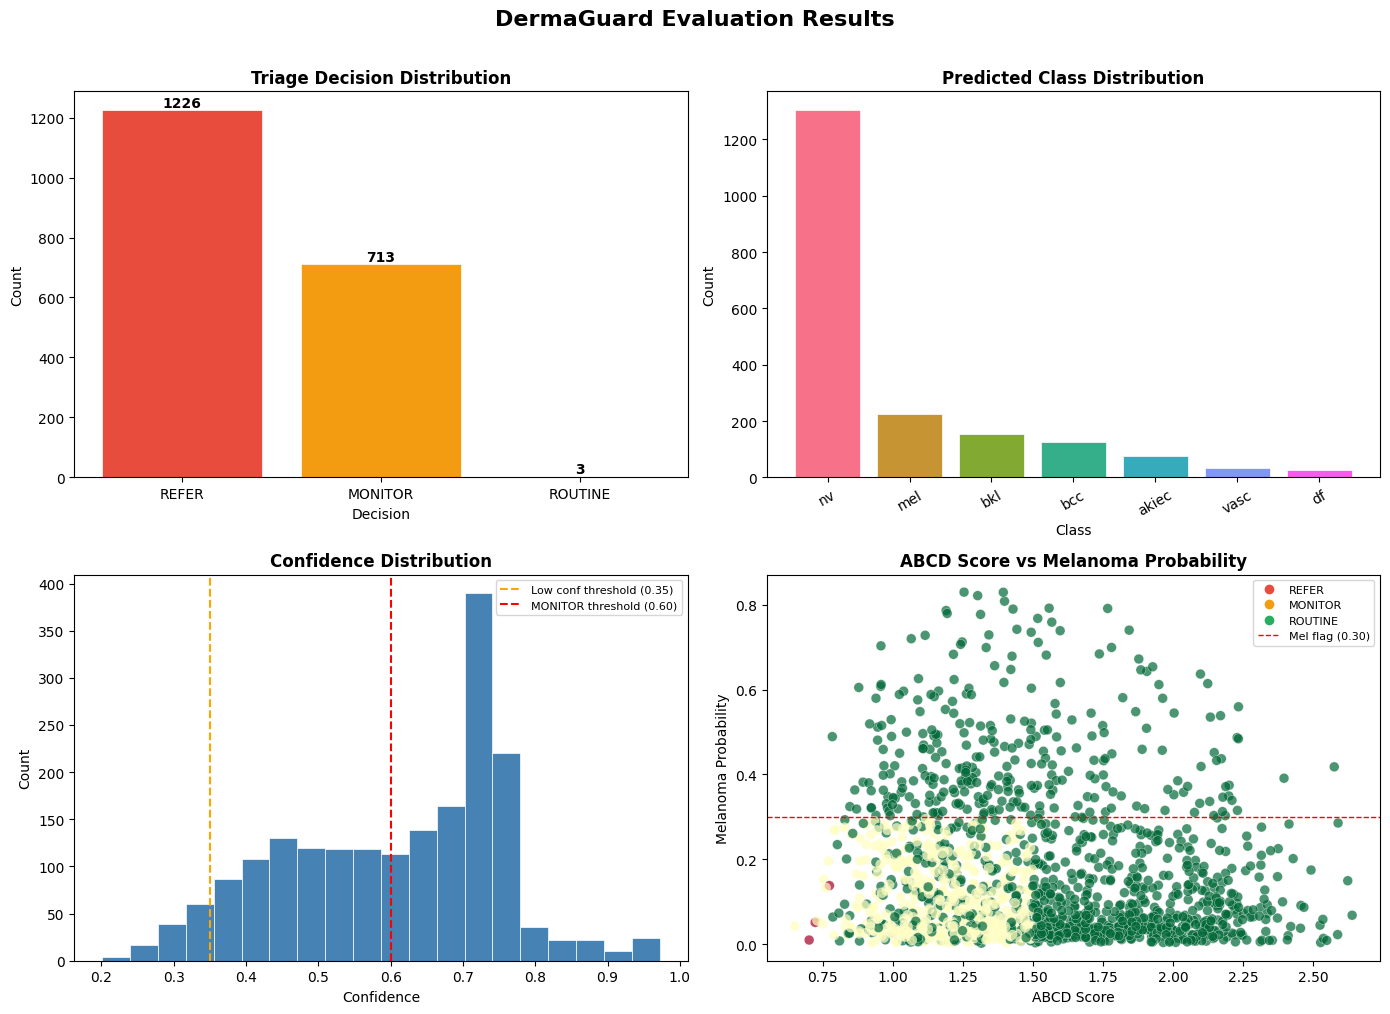

💾 Plot saved: /content/drive/MyDrive/dermaguard_eval_output/eval_summary_plot.png


In [17]:
# ── 4-panel visualisation ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("DermaGuard Evaluation Results", fontsize=16, fontweight="bold", y=1.01)

palette_dec = {"REFER": "#e74c3c", "MONITOR": "#f39c12", "ROUTINE": "#27ae60"}
palette_cls = sns.color_palette("husl", NUM_CLASSES)

# 1. Decision distribution
ax = axes[0, 0]
dec_counts = results_df["DECISION"].value_counts()
bars = ax.bar(dec_counts.index,
              dec_counts.values,
              color=[palette_dec.get(d, "steelblue") for d in dec_counts.index],
              edgecolor="white", linewidth=0.5)
for bar, val in zip(bars, dec_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, str(val),
            ha="center", va="bottom", fontweight="bold")
ax.set_title("Triage Decision Distribution", fontweight="bold")
ax.set_ylabel("Count"); ax.set_xlabel("Decision")

# 2. Predicted class distribution
ax = axes[0, 1]
cls_counts = results_df["predicted_class"].value_counts()
ax.bar(cls_counts.index, cls_counts.values,
       color=palette_cls[:len(cls_counts)], edgecolor="white", linewidth=0.5)
ax.set_title("Predicted Class Distribution", fontweight="bold")
ax.set_ylabel("Count"); ax.set_xlabel("Class")
ax.tick_params(axis="x", rotation=30)

# 3. Confidence histogram
ax = axes[1, 0]
ax.hist(results_df["confidence"], bins=20, color="steelblue",
        edgecolor="white", linewidth=0.5)
ax.axvline(0.35, color="orange", linestyle="--", label="Low conf threshold (0.35)")
ax.axvline(0.60, color="red",    linestyle="--", label="MONITOR threshold (0.60)")
ax.set_title("Confidence Distribution", fontweight="bold")
ax.set_xlabel("Confidence"); ax.set_ylabel("Count")
ax.legend(fontsize=8)

# 4. ABCD score vs melanoma probability
ax = axes[1, 1]
scatter = ax.scatter(results_df["abcd_score"],
                     results_df["melanoma_prob"],
                     c=[{"REFER": 0, "MONITOR": 1, "ROUTINE": 2}.get(d, 1)
                        for d in results_df["DECISION"]],
                     cmap="RdYlGn_r", alpha=0.7, edgecolors="white", linewidth=0.3, s=50)
ax.axhline(0.30, color="red", linestyle="--", linewidth=1, label="Mel flag (0.30)")
ax.set_title("ABCD Score vs Melanoma Probability", fontweight="bold")
ax.set_xlabel("ABCD Score"); ax.set_ylabel("Melanoma Probability")

# Combined Legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#e74c3c', label='REFER', markersize=8),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#f39c12', label='MONITOR', markersize=8),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#27ae60', label='ROUTINE', markersize=8),
    Line2D([0],[0], color='red', linestyle='--', linewidth=1, label='Mel flag (0.30)'),
]
ax.legend(handles=legend_elements, fontsize=8)

plt.tight_layout()
plot_path = OUTPUT_DIR / "eval_summary_plot.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"💾 Plot saved: {plot_path}")


## Step 10b · Accuracy Metrics *(only when labels are available)*

> This section automatically runs when `metadata.csv` with a `dx` column is present.  
> For the final 200 hidden test images (no labels), this section is silently skipped.

  ACCURACY METRICS  (labelled images only)
  Balanced Accuracy : 0.7646  (76.46%)
  Macro F1          : 0.7346
  Melanoma Recall   : 0.6215
  Labelled samples  : 1942

  Per-class results:
              precision    recall  f1-score   support

       akiec       0.49      0.59      0.53        63
         bcc       0.73      0.91      0.81       101
         bkl       0.77      0.56      0.65       212
          df       0.69      0.78      0.73        23
         mel       0.59      0.62      0.61       214
          nv       0.93      0.93      0.93      1302
        vasc       0.81      0.96      0.88        27

    accuracy                           0.84      1942
   macro avg       0.72      0.76      0.73      1942
weighted avg       0.85      0.84      0.84      1942



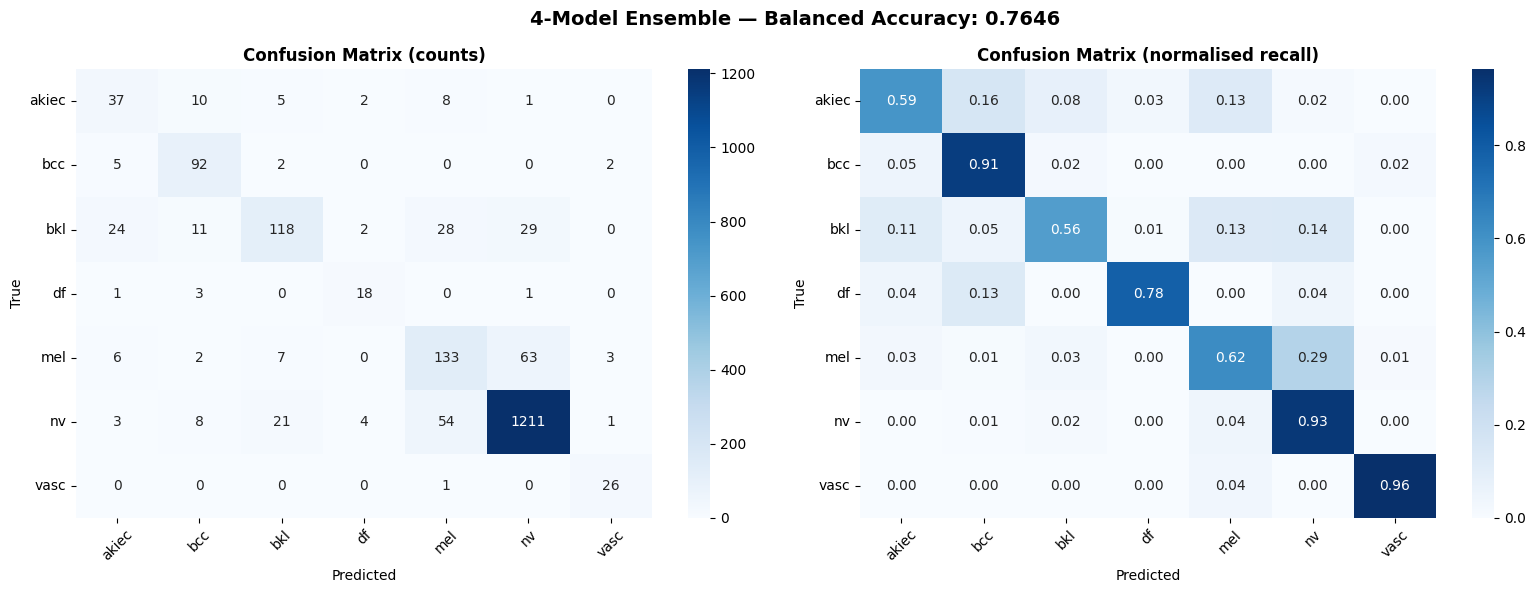


💾 Confusion matrix saved: /content/drive/MyDrive/dermaguard_eval_output/confusion_matrix.png
  🔴 Melanoma detection AUC: 0.9218
  ☁️  Confusion matrix saved to Drive


In [18]:
from sklearn.metrics import (balanced_accuracy_score, f1_score,
    recall_score, confusion_matrix, classification_report)

if not LABELS_AVAILABLE:
    print("ℹ️  Labels not available — skipping accuracy metrics")
    print("   (This is expected for the final hidden test set)")
else:
    # ── Filter to images with matched labels ─────────────────────────────────
    eval_df = results_df[results_df["true_label"].notna()].copy()
    y_true  = eval_df["true_label"].tolist()
    y_pred  = eval_df["predicted_class"].tolist()
    n       = len(eval_df)

    bal_acc = balanced_accuracy_score(y_true, y_pred)
    macro_f1= f1_score(y_true, y_pred, average="macro",  zero_division=0)
    mel_recall = recall_score(y_true, y_pred, labels=["mel"],
                              average="macro", zero_division=0)

    print("=" * 60)
    print("  ACCURACY METRICS  (labelled images only)")
    print("=" * 60)
    print(f"  Balanced Accuracy : {bal_acc:.4f}  ({bal_acc*100:.2f}%)")
    print(f"  Macro F1          : {macro_f1:.4f}")
    print(f"  Melanoma Recall   : {mel_recall:.4f}")
    print(f"  Labelled samples  : {n}")
    print()
    print("  Per-class results:")
    print(classification_report(y_true, y_pred, zero_division=0))

    # ── Confusion matrix ─────────────────────────────────────────────────────
    present_classes = sorted(set(y_true) | set(y_pred))
    cm      = confusion_matrix(y_true, y_pred, labels=present_classes)
    cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-8)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, data, fmt, title in zip(
        axes,
        [cm, cm_norm],
        ["d", ".2f"],
        ["Confusion Matrix (counts)", "Confusion Matrix (normalised recall)"]
    ):
        sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues",
                    xticklabels=present_classes, yticklabels=present_classes, ax=ax)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        ax.set_title(title, fontweight="bold")
        ax.tick_params(axis="x", rotation=45)
        ax.tick_params(axis="y", rotation=0)

    fig.suptitle(f"4-Model Ensemble — Balanced Accuracy: {bal_acc:.4f}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    cm_path = OUTPUT_DIR / "confusion_matrix.png"
    plt.savefig(cm_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\n💾 Confusion matrix saved: {cm_path}")

    # ── Melanoma detection summary ────────────────────────────────────────────
    mel_idx      = LABEL_MAP.get("mel", 1)
    true_mel     = [1 if t == "mel" else 0 for t in y_true]
    flagged_mel  = [1 if f else 0 for f in eval_df["melanoma_flag"]]
    from sklearn.metrics import roc_auc_score
    try:
        auc = roc_auc_score(true_mel, eval_df["melanoma_prob"].tolist())
        print(f"  🔴 Melanoma detection AUC: {auc:.4f}")
    except Exception:
        pass

    # ── Back to Drive ─────────────────────────────────────────────────────────
    shutil.copy2(cm_path, drive_out / cm_path.name)
    print(f"  ☁️  Confusion matrix saved to Drive")


## Step 11 · Inspect REFER Cases (Malignant / High-Risk)

In [19]:
refer_df = results_df[results_df["DECISION"] == "REFER"].copy()
print(f"🔴 REFER cases: {len(refer_df)}")
if len(refer_df) > 0:
    display(refer_df[["image_id", "predicted_class", "confidence", "melanoma_prob",
                       "malignant_prob", "safety_flags", "urgency",
                       "patient_risk", "lesion_risk"]].head(20))

🔴 REFER cases: 1226


,image_id,predicted_class,confidence,melanoma_prob,malignant_prob,safety_flags,urgency,patient_risk,lesion_risk
1,ISIC_0024330,df,0.4314,0.0231,0.4330,malignant_prob=0.433>0.40,SOON,MODERATE,MODERATE
2,ISIC_0024332,bcc,0.7347,0.0232,0.8607,malignant_dx=bcc | malignant_prob=0.861>0.40,SOON,MODERATE,MODERATE
5,ISIC_0024346,nv,0.7192,0.0325,0.1344,high_lesion_suspicion (ABCD=2.00),SOON,MODERATE,HIGH
6,ISIC_0024349,nv,0.4967,0.3113,0.3799,melanoma_flag (mel_prob=0.311),URGENT,MODERATE,MODERATE
8,ISIC_0024358,bkl,0.3757,0.3101,0.4183,melanoma_flag (mel_prob=0.310) | malignant_pro...,URGENT,HIGH,MODERATE
9,ISIC_0024360,bcc,0.7776,0.0230,0.8298,malignant_dx=bcc | malignant_prob=0.830>0.40 |...,SOON,MODERATE,HIGH
10,ISIC_0024368,nv,0.7679,0.0176,0.0904,patient_risk=HIGH + lesion_risk=MODERATE,SOON,HIGH,MODERATE
11,ISIC_0024370,vasc,0.9569,0.0031,0.0204,high_lesion_suspicion (ABCD=1.51),SOON,MODERATE,HIGH
12,ISIC_0024372,mel,0.3973,0.3973,0.7939,malignant_dx=mel | melanoma_flag (mel_prob=0.3...,URGENT,HIGH,MODERATE
13,ISIC_0024377,nv,0.4282,0.3711,0.4425,melanoma_flag (mel_prob=0.371) | malignant_pro...,URGENT,MODERATE,MODERATE


## Step 12 · Sample Image Grid with Predictions

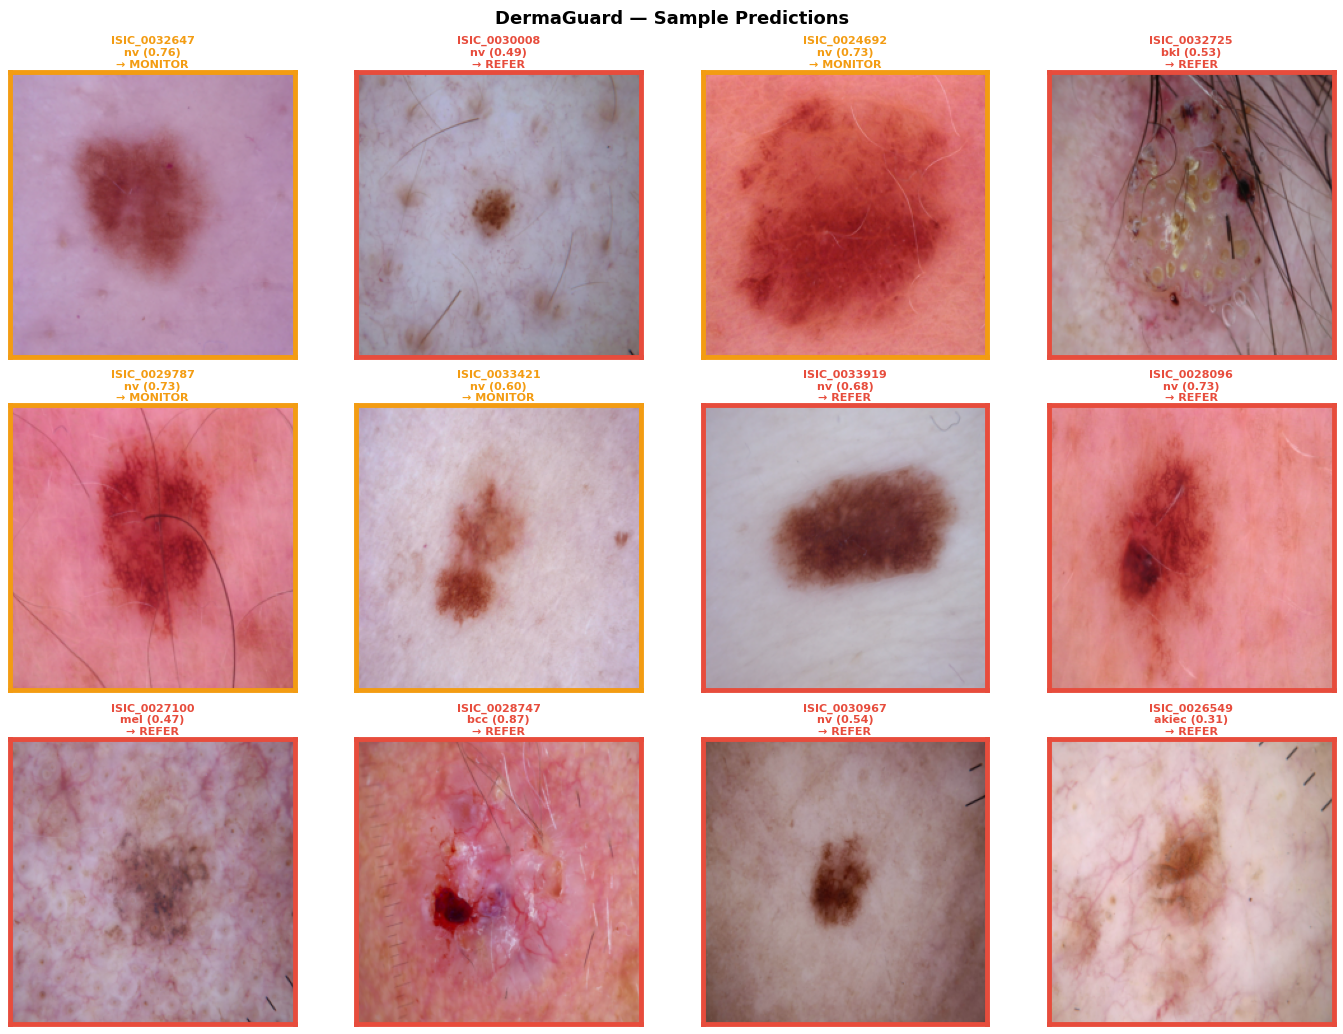

💾 Sample grid saved


In [20]:
def show_sample_grid(df, n=12, title="Sample Predictions"):
    """Display a grid of sample images with their predictions."""
    sample = df.sample(min(n, len(df)), random_state=42)
    cols   = 4
    rows   = (len(sample) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.5))
    axes = axes.flatten()

    dec_colors = {"REFER": "#e74c3c", "MONITOR": "#f39c12", "ROUTINE": "#27ae60"}

    for i, (_, row) in enumerate(sample.iterrows()):
        found = None
        for ext in [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]:
            p = EVAL_IMAGE_DIR / f"{row['image_id']}{ext}"
            if p.exists():
                found = p; break

        ax = axes[i]
        if found:
            img = Image.open(found).convert("RGB").resize((224, 224), RESAMPLE)
            ax.imshow(img)
        else:
            ax.set_facecolor("#222")
            ax.text(0.5, 0.5, "Not found", ha="center", va="center",
                    color="white", transform=ax.transAxes)

        dec   = row["DECISION"]
        color = dec_colors.get(dec, "gray")
        title_str = (f"{row['image_id'][:12]}\n"
                     f"{row['predicted_class']} ({row['confidence']:.2f})\n"
                     f"→ {dec}")
        ax.set_title(title_str, fontsize=8, color=color, fontweight="bold", pad=3)
        ax.set_xticks([])
        ax.set_yticks([])

        # Coloured border
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(3.5)

    # Hide unused axes
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "sample_grid.png", dpi=150, bbox_inches="tight")
    plt.show()

show_sample_grid(results_df, n=12, title="DermaGuard — Sample Predictions")
print("💾 Sample grid saved")


## Step 13 · Final Output Files

In [21]:
print("=" * 60)
print("  DERMAGUARD EVALUATION — COMPLETE ✅")
print("=" * 60)
print()
print("📂 Output files saved to:")
for f in sorted(OUTPUT_DIR.iterdir()):
    size_kb = f.stat().st_size / 1024
    print(f"   {f.name:<40}  ({size_kb:.1f} KB)")
print()
print("☁️  All results also backed up to:")
print(f"   Google Drive: {drive_out}")
print()
print("📋 Submission CSV columns:")
print(f"   {sub_df.columns.tolist()}")
print()
print("📊 Final class distribution in submission:")
print(results_df["predicted_class"].value_counts().to_string())
print()
print("🩺 Final decision breakdown:")
print(results_df["DECISION"].value_counts().to_string())

  DERMAGUARD EVALUATION — COMPLETE ✅

📂 Output files saved to:
   confusion_matrix.png                      (125.2 KB)
   dermaguard_eval_full.csv                  (714.0 KB)
   dermaguard_submission.csv                 (188.2 KB)
   eval_summary_plot.png                     (442.7 KB)
   sample_grid.png                           (2341.1 KB)

☁️  All results also backed up to:
   Google Drive: /content/drive/MyDrive/dermaguard_results

📋 Submission CSV columns:
   ['image_id', 'true_label', 'predicted_class', 'confidence', 'melanoma_flag', 'melanoma_prob', 'DECISION', 'urgency', 'safety_flags']

📊 Final class distribution in submission:
predicted_class
nv       1305
mel       224
bkl       153
bcc       126
akiec      76
vasc       32
df         26

🩺 Final decision breakdown:
DECISION
REFER      1226
MONITOR     713
ROUTINE       3
